In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from keras.models import Sequential
from keras.layers import Dense
from tensorflow.keras.metrics import Precision, Recall

In [3]:
df=pd.read_csv('PreprocessedData (7).csv', encoding='latin1')
df.head()

,Unnamed: 0,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Name,shipping date (DateOrders),Shipping Mode
0,0,1,3,4,314.640015,0,0,73,40,65,...,1,327.75,91.250000,15,475,2,1360,78,3250,3
1,1,3,5,4,311.359985,1,1,73,40,65,...,1,327.75,-249.089996,13,841,5,1360,78,20134,3
2,2,0,4,4,309.720001,3,0,73,40,451,...,1,327.75,-247.779999,13,841,1,1360,78,19905,3
3,3,1,3,4,304.809998,0,0,73,40,284,...,1,327.75,22.860001,11,835,2,1360,78,19677,3
4,4,2,2,4,298.250000,0,0,73,40,65,...,1,327.75,134.210007,11,835,6,1360,78,19453,3


In [4]:
y = df['Late_delivery_risk']
X = df.drop(columns=['Late_delivery_risk','Unnamed: 0','Longitude', 'Customer State',
'Category Id','Order Country','Product Card Id','Order Customer Id',
'shipping date (DateOrders)',
'Customer Segment',	'Order Item Id','Category Name','Order State','Department Id','Customer Country',
'Customer Street','Order Item Discount',
'Latitude','order date (DateOrders)',
'Market','Order Item Discount Rate','Order Item Quantity'])

## Split the dataset into training and testing sets (e.g., 80% training, 20% testing):
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## standardize the feature values:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
## Importing sequential and dense layers from keras:
from keras.models import Sequential
from keras.layers import Dense

## Create an instance of a "Sequential" model:
#Sequential is used to stack the layers of the neural network model
model = Sequential()

In [6]:
X.shape

(180516, 17)

In [7]:
shape=X.shape[1]
shape

17

In [8]:
#Add the stack of layers needed in the model
model.add(Dense(16, input_shape=(shape,), activation='relu'))
model.add(Dense(8, activation='relu'))#for non-linearity
model.add(Dense(1, activation='sigmoid'))#for binary classification

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
#Configure the model by choosing the optimizer and how to calculate errors and what metrics we need to evaluate
#Adam is an optimizer for weights
#Binary crossentropy used for binary classification
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', Precision(name='precision'), Recall(name='recall')])

In [10]:
#training
#epochs= go through data 20 times and update weights for each pass
#80% for training, 20% for testing
history = model.fit(X_train, y_train, epochs = 20, validation_split=0.2)

Epoch 1/20
3611/3611 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - accuracy: 0.9303 - loss: 0.1794 - precision: 0.9111 - recall: 0.9763 - val_accuracy: 0.9999 - val_loss: 8.4407e-04 - val_precision: 0.9999 - val_recall: 1.0000
Epoch 2/20
3611/3611 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 1.0000 - loss: 3.8849e-04 - precision: 0.9999 - recall: 1.0000 - val_accuracy: 0.9999 - val_loss: 1.2578e-04 - val_precision: 1.0000 - val_recall: 0.9999
Epoch 3/20
3611/3611 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 1.0000 - loss: 6.7734e-05 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 1.0180e-05 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/20
3611/3611 ━━━━━━━━━━━━━━━━━━━━ 25s 4ms/step - accuracy: 1.0000 - loss: 2.7362e-05 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 1.7767e-06 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 5/20
3611/3611 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 1.0000 - loss: 1.2617e-06 - precision: 1.0000 - recal

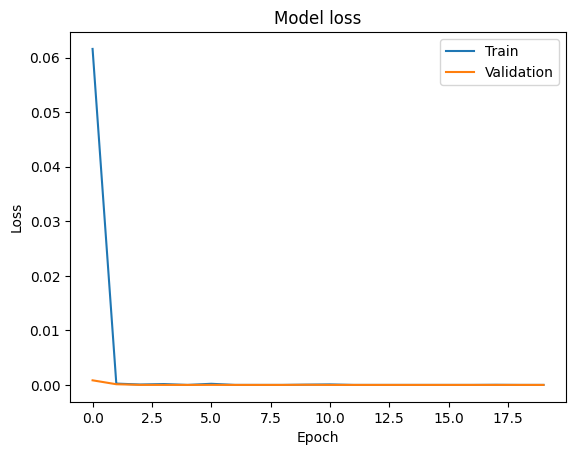

In [11]:
## Plot training & validation loss values:

import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

In [12]:
#test model on unseen data
results = model.evaluate(X_test, y_test)
results

1129/1129 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 1.0000 - loss: 1.7998e-08 - precision: 1.0000 - recall: 1.0000


[1.3850129931824995e-08, 1.0, 1.0, 1.0]

In [13]:
print("Test Loss:", results[0])
print("Test Accuracy:", results[1])
print("Test Precision:", results[2])
print("Test Recall:", results[3])

Test Loss: 1.3850129931824995e-08
Test Accuracy: 1.0
Test Precision: 1.0
Test Recall: 1.0
